# Sumativa 3 del Grupo 7
## Modelamiento predictivo integrado de lluvia

**MCDI501 · Universidad Andrés Bello**  
**Integrantes:** Benjamín Araya, Alan Cañete, Patricio Cortez y Jorge Guaico.

La clasificación de `RainTomorrow` utiliza la evidencia de S1 y S2 y el modelo
de F2 como referencia reproducible. La pregunta es cómo cambia la detección de
lluvia al comparar imputación, selección de variables y estabilidad de coeficientes.
El ejercicio utiliza información histórica del día registrado y no certifica un
servicio de pronóstico ni disponibilidad operacional a una hora específica.

**Productos:** análisis ejecutable, resultados JSON/CSV, nueve figuras, informe
LaTeX/PDF y presentación con guion. La grabación grupal y la entrega Canvas se
acreditan por separado. La rúbrica vigente suma **108 puntos**.

El código estadístico está en `src/sumativa3.py`. Todas las etapas se calculan
de nuevo al ejecutar este cuaderno: no se reemplazan ajustes por resultados
guardados de Work. Las celdas finales reúnen las visualizaciones de esta ejecución.

## 1 Configuración y procedencia

Se comprueba el SHA-256 del CSV original. La semilla 42 conserva la partición
70/30 estratificada de F2 sobre 142.193 respuestas conocidas. Las respuestas
ausentes se excluyen y `RainTomorrow` se usa exclusivamente como objetivo.
Las otras semillas y el número de remuestras permanecen visibles aquí.

In [1]:
from pathlib import Path
import sys
from IPython.display import display, Markdown, Image

raiz = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src/sumativa3.py").is_file()
             and (p / "data/raw/weatherAUS.csv").is_file()), None)
if raiz is None:
    raise FileNotFoundError("Abre el notebook dentro del proyecto con data/raw/weatherAUS.csv")
sys.path.insert(0, str(raiz / "src"))
import sumativa3 as s3

SEMILLA_PARTICION = 42
SEMILLA_IMPUTACION = 50101
SEMILLA_VALIDACION = 50102
SEMILLA_BOOTSTRAP = 50103
SEMILLA_MONTECARLO = 50104
REPLICAS_BOOTSTRAP = 2000
PLIEGUES_VALIDACION = 5
ITERACIONES_MONTECARLO = 10000

configuracion = s3.Config(
    semilla_particion=SEMILLA_PARTICION,
    semilla_imputacion=SEMILLA_IMPUTACION,
    semilla_cv=SEMILLA_VALIDACION,
    semilla_bootstrap=SEMILLA_BOOTSTRAP,
    semilla_mc=SEMILLA_MONTECARLO,
    bootstrap_replicas=REPLICAS_BOOTSTRAP,
    folds=PLIEGUES_VALIDACION,
    montecarlo_iteraciones=ITERACIONES_MONTECARLO,
)
print("Python:", sys.version.split()[0])
print("Proyecto:", raiz.name)
print("Semillas y remuestreo:", vars(configuracion))
ctx = s3.iniciar(configuracion)
display(s3.pd.read_csv(ctx["tables"] / "particion.csv"))

Python: 3.12.0
Proyecto: Proyecto-Lluvias-Australia-Grupo7
Semillas y remuestreo: {'semilla_particion': 42, 'semilla_imputacion': 50101, 'semilla_cv': 50102, 'semilla_bootstrap': 50103, 'semilla_mc': 50104, 'bootstrap_replicas': 2000, 'folds': 5, 'montecarlo_iteraciones': 10000}


Datos: 145,460 filas; 142,193 respuestas conocidas; 16 numéricas.
Train=99,535; test=42,658; semilla=42.


,conjunto,n,n_lluvia,lluvia_pct,localidades
0,train,99535,22314,22.418245,49
1,test,42658,9563,22.417835,49


## 2 Reproducción independiente de la referencia F2

Se reconstruye el modelo no ponderado con Humidity3pm, Sunshine, Rainfall y
MaxTemp, mediana, StandardScaler y umbral 0,50. Los ajustes usan entrenamiento.
Las cinco métricas y los cuatro conteos de la matriz se contrastan con la entrega
calificada, antes de evaluar propuestas nuevas. Esto separa continuidad de mejora.

In [2]:
referencia_F2 = s3.reproducir_f2(ctx)
display(referencia_F2)

F2 reproducida: AUC 0.816389 recall 0.398201


,metrica,F2_entregada,reproducida_S3,diferencia
0,accuracy,0.828848,0.828848,0.0
1,precision,0.711244,0.711244,0.0
2,recall,0.398201,0.398201,0.0
3,f1,0.510558,0.510558,0.0
4,auc,0.816389,0.816389,0.0


## 3 Imputación mediante regresión múltiple

Se recuperan de S1 los porcentajes de faltantes. El 48,01% de Sunshine corresponde
al CSV completo y el 47,69% a respuestas conocidas. Diecinueve estaciones carecen
de Sunshine observado: la ausencia depende de localidad. MAR condicionado a
covariables es un supuesto de trabajo; el archivo no permite descartar MNAR.

La matriz exportada en S1 contiene siete variables. Para las demás relaciones,
se calcula una ampliación de S3 exclusivamente en entrenamiento, identificada
en las tablas. Se priorizan los pares validados en S2 y se eligen tres predictores
por variable, reduciendo redundancia entre ellos. Se ajustan 16 regresiones OLS
con casos completos del correspondiente objetivo y predictores de entrenamiento.

La validación interna retiene el 20% de donantes observados. Compara reconstrucción
con mediana mediante RMSE, MAE y R². No valida los valores desconocidos de las
estaciones sin Sunshine. Si faltan covariables al aplicar una regresión, se utiliza
su mediana auxiliar de entrenamiento. Se registran estos casos y los recortes
aplicados exclusivamente a predicciones imputadas fuera de rangos admisibles.
Los valores originales observados permanecen intactos.

**Regla predefinida:** se usa regresión como estrategia principal si reduce al
menos 5% el RMSE de Sunshine frente a mediana en esa validación de donantes;
en caso contrario se usa mediana. Esta elección precede a las métricas de prueba.

In [3]:
diagnosticos_imputacion = s3.estudiar_imputacion(ctx)
display(diagnosticos_imputacion)
display(Markdown(s3.interpretar(ctx, "imputacion")))

Ajustando regresiones de imputación sobre casos completos de entrenamiento...


Imputación principal: regresion; reducción RMSE Sunshine=41.76%.


,variable,predictores,n_ajuste_completos,n_validacion_interna,r2_ajuste,r2_validacion,rmse_regresion,rmse_mediana,mae_regresion,shapiro_p_muestra_5000,breusch_pagan_p,vif_max,rango_predicho_min,rango_predicho_max
0,MinTemp,Temp9am; Evaporation; Pressure3pm,56512,11303,0.823843,0.827194,2.689049,6.479454,2.144984,3.513567e-34,2.091105e-268,1.732127,-3.899533,30.439074
1,MaxTemp,Temp3pm; MinTemp; Evaporation,56017,11204,0.973373,0.972959,1.156705,7.055424,0.771892,1.043011e-57,0.000000e+00,2.432577,7.148176,47.503135
2,Rainfall,Humidity3pm; Humidity9am; Sunshine,51140,10228,0.075307,0.080635,8.503152,9.181434,3.371816,3.428167e-85,3.632873e-97,2.392622,0.000000,8.499913
3,Evaporation,MaxTemp; MinTemp; Humidity9am,56479,11296,0.422036,0.416747,3.265610,4.332337,1.906511,8.019491e-76,1.507869e-38,3.111829,0.000000,15.824893
4,Sunshine,Humidity3pm; Cloud3pm; Cloud9am,44903,8981,0.648037,0.644519,2.225664,3.821609,1.793021,2.324640e-09,0.000000e+00,1.756962,1.605126,14.177293
5,WindGustSpeed,WindSpeed3pm; WindSpeed9am; Pressure9am,85703,17141,0.617051,0.616814,8.271369,13.409392,6.137409,7.573395e-44,0.000000e+00,1.421261,10.370275,92.720395
6,WindSpeed9am,WindGustSpeed; WindSpeed3pm; Humidity9am,91836,18368,0.407887,0.404438,6.693930,8.744881,5.288889,9.427776e-06,0.000000e+00,1.955184,0.000000,44.245057
7,WindSpeed3pm,WindGustSpeed; WindSpeed9am; Pressure9am,85703,17141,0.491691,0.481558,6.146958,8.537125,4.747237,8.862139e-14,0.000000e+00,1.886518,4.737876,67.029826
8,Humidity9am,Humidity3pm; Evaporation; Sunshine,48718,9744,0.548139,0.543338,12.597168,18.650772,9.850338,1.238666e-08,0.000000e+00,1.754075,0.000000,100.000000
9,Humidity3pm,Sunshine; Rainfall; Humidity9am,51140,10228,0.584980,0.587566,13.129231,20.452321,10.574025,1.365617e-07,1.456116e-17,1.347019,6.272393,100.000000


**Reconstrucción de Sunshine:** RMSE de 3.822 horas con mediana y 2.226 con regresión, una reducción de 41.8%. La regla de entrenamiento seleccionó **regresion**. Los donantes completos no representan las 19 localidades sin Sunshine. Los rechazos de normalidad y homocedasticidad se conservan como limitaciones; la regresión predice un valor condicional, no reconstruye la variabilidad desconocida.

## 4 Tres procedimientos de selección logística

- **M1 de dominio:** conserva los cuatro predictores de F2 informados por S1/S2.
- **M2 stepwise AIC:** incorpora o retira candidatos justificables. Incluye
  log1p(Rainfall), que conserva la información de lluvias extremas y su orden,
  y evita la redundancia MaxTemp–Temp3pm. Los candidatos adicionales se documentan
  como ampliación de S3 cuando no estaban en la matriz parcial de S1.
- **M3 reducido BIC:** elige el menor BIC entre subconjuntos de uno a tres
  predictores del modelo de dominio. Es una búsqueda restringida por parsimonia,
  no el mínimo BIC entre todos los modelos posibles.

AIC/BIC se calculan con verosimilitud no ponderada sobre las mismas filas.
Después se reajustan las tres especificaciones con pesos balanceados
`n / (2 * n_clase)`, calculados en entrenamiento. El peso aproximado 2,23 para
lluvia se acompaña de un peso cercano a 0,64 para ausencia de lluvia.

La validación estratificada de cinco pliegues reajusta imputación y escalamiento
en cada entrenamiento interno. Repite la selección AIC/BIC dentro del pliegue.
Se elige el mayor AUC OOF; diferencias de hasta 0,002 favorecen parsimonia.
Cada umbral maximiza F1 utilizando únicamente predicciones OOF de entrenamiento.
Los modelos y umbrales se registran antes de evaluar prueba.

In [4]:
seleccion = s3.ajustar_modelos(ctx)
display(seleccion)
display(s3.pd.read_csv(ctx["tables"] / "coeficientes_tres_modelos.csv"))
for nombre, modelo in ctx["models"].items():
    print("\nResumen del ajuste ponderado:", nombre)
    print(modelo["fit"].summary())
display(Markdown(s3.interpretar(ctx, "modelos")))

CV regresion: pliegue 1/5 terminado


CV regresion: pliegue 2/5 terminado


CV regresion: pliegue 3/5 terminado


CV regresion: pliegue 4/5 terminado


CV regresion: pliegue 5/5 terminado


Modelo elegido exclusivamente en entrenamiento: M2_stepwise_AIC ['Humidity3pm', 'WindGustSpeed', 'Pressure3pm', 'Sunshine', 'log1p_Rainfall', 'Cloud3pm', 'MaxTemp', 'Humidity9am']
Umbral F1 OOF: 0.603429598311056


,modelo,n_predictores,predictores,AIC_seleccion_no_ponderado,BIC_seleccion_no_ponderado,umbral_F1_OOF,oof_n,oof_umbral,oof_accuracy,oof_precision,oof_recall,oof_f1,oof_auc,oof_pr_auc,oof_tn,oof_fp,oof_fn,oof_tp
0,M1_dominio,4,Humidity3pm; Sunshine; Rainfall; MaxTemp,80289.235461,80336.776784,0.563803,99535,0.563803,0.779053,0.505472,0.666487,0.574919,0.821334,0.610882,62671,14550,7442,14872
1,M2_stepwise_AIC,8,Humidity3pm; WindGustSpeed; Pressure3pm; Sunsh...,72746.507956,72832.082337,0.603430,99535,0.603430,0.815633,0.575540,0.676571,0.621980,0.860435,0.676759,66087,11134,7217,15097
2,M3_reducido_BIC,3,Humidity3pm; Sunshine; Rainfall,80848.302314,80886.335372,0.577570,99535,0.577570,0.783282,0.513164,0.649010,0.573147,0.817981,0.607704,63482,13739,7832,14482


,modelo,estrategia,termino,coeficiente,error_estandar_convencional,ic_wald_beta_inf,ic_wald_beta_sup,odds_ratio,ic_wald_OR_inf,ic_wald_OR_sup,p_convencional,coeficiente_unidad_original_o_log1p,DE_referencia
0,M1_dominio,regresion,const,-0.414926,0.008141,-0.430883,-0.398970,0.660389,0.649935,0.671011,0.000000e+00,-2.083546,NaN
1,M1_dominio,regresion,Humidity3pm,0.894482,0.011037,0.872849,0.916115,2.446068,2.393721,2.499560,0.000000e+00,0.043411,20.604906
2,M1_dominio,regresion,Sunshine,-0.659827,0.010415,-0.680240,-0.639414,0.516941,0.506496,0.527601,0.000000e+00,-0.214631,3.074242
3,M1_dominio,regresion,Rainfall,0.383951,0.012105,0.360225,0.407676,1.468073,1.433652,1.503320,8.790741e-221,0.045456,8.446678
4,M1_dominio,regresion,MaxTemp,0.272175,0.009012,0.254511,0.289838,1.312816,1.289830,1.336211,2.346184e-200,0.038214,7.122410
5,M2_stepwise_AIC,regresion,const,-0.578647,0.008848,-0.595990,-0.561304,0.560656,0.551017,0.570464,0.000000e+00,69.523253,NaN
6,M2_stepwise_AIC,regresion,Humidity3pm,0.902112,0.012919,0.876792,0.927431,2.464802,2.403177,2.528007,0.000000e+00,0.043781,20.604906
7,M2_stepwise_AIC,regresion,WindGustSpeed,0.467480,0.009232,0.449387,0.485574,1.595968,1.567351,1.625107,0.000000e+00,0.034837,13.419246
8,M2_stepwise_AIC,regresion,Pressure3pm,-0.486389,0.009894,-0.505781,-0.466997,0.614843,0.603034,0.626882,0.000000e+00,-0.072710,6.689402
9,M2_stepwise_AIC,regresion,Sunshine,-0.478283,0.013908,-0.505542,-0.451023,0.619847,0.603178,0.636976,3.758134e-259,-0.155577,3.074242



Resumen del ajuste ponderado: M1_dominio
                 Generalized Linear Model Regression Results                  
Dep. Variable:                      y   No. Observations:                99535
Model:                            GLM   Df Residuals:                    99530
Model Family:                Binomial   Df Model:                            4
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -51529.
Date:                Sun, 25 Oct 2026   Deviance:                   1.0306e+05
Time:                        15:18:36   Pearson chi2:                 2.00e+05
No. Iterations:                     6   Pseudo R-squ. (CS):             0.2960
Covariance Type:            nonrobust                                         
                  coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------
const   

La selección OOF eligió **M2_stepwise_AIC** con 8 predictores. Su umbral 0.6034 maximiza F1 OOF. La selección AIC/BIC es no ponderada y usa las mismas filas; los modelos predictivos se reajustan con pesos balanceados. M3 minimiza BIC entre subconjuntos de uno a tres predictores de dominio, no entre todos los modelos posibles.

## 5 Desempeño de entrenamiento y prueba

Se calculan matrices, accuracy, precision, recall, F1, ROC-AUC y PR-AUC adicional.
Se presentan los umbrales OOF y el 0,50 como referencia. Los pesos no cambian
la proporción real de clases utilizada al evaluar métricas.

El AUC resume discriminación, no porcentaje de aciertos. Los scores del ajuste
ponderado no equivalen automáticamente a probabilidades calibradas. La prueba
ya fue observada en F2 y los antecedentes exploraron el archivo completo:
esta comparación no constituye una validación externa independiente.

In [5]:
metricas = s3.evaluar_modelos(ctx)
display(metricas)
display(Markdown(s3.interpretar(ctx, "rendimiento")))

,modelo,conjunto,regla_umbral,n,umbral,accuracy,precision,recall,f1,auc,pr_auc,tn,fp,fn,tp
0,M1_dominio,train,F1_OOF,99535,0.563803,0.779022,0.505421,0.666487,0.574885,0.821418,0.611119,62668,14553,7442,14872
1,M1_dominio,train,referencia_0.5,99535,0.500000,0.748430,0.461342,0.728959,0.565066,0.821418,0.611119,58229,18992,6048,16266
2,M1_dominio,test,F1_OOF,42658,0.563803,0.780627,0.508172,0.666527,0.576676,0.823976,0.622561,26926,6169,3189,6374
3,M1_dominio,test,referencia_0.5,42658,0.500000,0.749308,0.462527,0.729896,0.566237,0.823976,0.622561,24984,8111,2583,6980
4,M2_stepwise_AIC,train,F1_OOF,99535,0.603430,0.815492,0.575239,0.676526,0.621785,0.860551,0.676905,66074,11147,7218,15096
5,M2_stepwise_AIC,train,referencia_0.5,99535,0.500000,0.784046,0.512298,0.764453,0.613476,0.860551,0.676905,60982,16239,5256,17058
6,M2_stepwise_AIC,test,F1_OOF,42658,0.603430,0.817924,0.579751,0.682631,0.626999,0.861933,0.687208,28363,4732,3035,6528
7,M2_stepwise_AIC,test,referencia_0.5,42658,0.500000,0.783581,0.511579,0.764614,0.613011,0.861933,0.687208,26114,6981,2251,7312
8,M3_reducido_BIC,train,F1_OOF,99535,0.577570,0.783202,0.513004,0.649727,0.573327,0.818076,0.607853,63458,13763,7816,14498
9,M3_reducido_BIC,train,referencia_0.5,99535,0.500000,0.743939,0.455725,0.731828,0.561680,0.818076,0.607853,57718,19503,5984,16330


En esta prueba, AUC=0.8619, recall=68.26%, precision=57.98% y accuracy=81.79%. Quedan 3,035 días de lluvia sin detectar. F2 tenía recall=39.82% y accuracy=82.88%. La comparación cambia variables, imputación, pesos y umbral: no atribuye la mejora a una sola causa. El score ponderado necesita calibración antes de interpretarse como probabilidad operacional.

## 6 Impacto de imputación en la especificación final

Se mantiene la misma lista de predictores y el mismo umbral seleccionado.
Se reajusta el modelo final con eliminación, mediana y regresión, usando siempre
los índices originales de entrenamiento y prueba. Se comparan tamaño, localidades,
distribuciones, correlaciones, coeficientes, IC, accuracy y AUC.

La eliminación cambia la cobertura geográfica y el conjunto evaluado. Por eso,
además de las métricas disponibles por estrategia, se informa una comparación
sobre los mismos casos completos de prueba. Los coeficientes y OR usan la DE
de referencia del modelo principal para evitar comparar escalas distintas.
La comparación constituye sensibilidad de una decisión fijada en entrenamiento.

In [6]:
impacto = s3.comparar_imputacion(ctx)
display(impacto)
display(Markdown(s3.interpretar(ctx, "impacto")))

,estrategia,poblacion_prueba,n_train,localidades_train,localidades_test,cobertura_test,n,umbral,accuracy,precision,recall,f1,auc,pr_auc,tn,fp,fn,tp
0,eliminacion,disponible_por_estrategia,42282,27,27,0.427446,18234,0.60343,0.828288,0.592739,0.709814,0.646015,0.881319,0.721846,12246,1963,1168,2857
1,eliminacion,casos_comunes,42282,27,27,0.427446,18234,0.60343,0.828288,0.592739,0.709814,0.646015,0.881319,0.721846,12246,1963,1168,2857
2,mediana,disponible_por_estrategia,99535,49,49,1.000000,42658,0.60343,0.816846,0.578069,0.677507,0.623851,0.858940,0.682738,28366,4729,3084,6479
3,mediana,casos_comunes,99535,49,27,0.427446,18234,0.60343,0.821432,0.574704,0.734907,0.645007,0.880119,0.722100,12020,2189,1067,2958
4,regresion,disponible_por_estrategia,99535,49,49,1.000000,42658,0.60343,0.817924,0.579751,0.682631,0.626999,0.861933,0.687208,28363,4732,3035,6528
5,regresion,casos_comunes,99535,49,27,0.427446,18234,0.60343,0.829769,0.596118,0.709565,0.647913,0.880895,0.720444,12274,1935,1169,2856


La eliminación cubre 42.74% de prueba y 27 localidades. Su AUC disponible no es directamente comparable con el de métodos que conservan toda la muestra. La tabla de casos comunes controla el conjunto evaluado. Los coeficientes se comparan por la misma DE de referencia, evitando confundir cambios de escala con cambios de efecto.

## 7 Estabilidad por bootstrap de localidades

Se remuestrean con reemplazo las 49 localidades de entrenamiento y se conservan
sus registros disponibles juntos. Se reajustan regresiones de imputación,
medianas auxiliares, escala y pesos de clase. Las especificaciones del clasificador
y de las regresiones de imputación permanecen fijadas: los intervalos son
condicionales a esa selección. La independencia espacial sigue sin demostrarse.

El cálculo usa multiplicidades de localidad equivalentes a duplicar filas.
Antes del remuestreo se verifica esa equivalencia contra una expansión real
y un GLM independiente. Se expresan todas las betas por la misma DE de referencia.
Se obtienen IC percentil, IC BCa con jackknife de 49 localidades y OR como
transformación exponencial de los extremos. Se comparan con IC Wald convencionales.
La rúbrica no fija una cantidad mínima de remuestras en S3: 2.000 es la decisión
metodológica aprobada. Se registra el número real de intentos y fallos.

In [7]:
intervalos_bootstrap = s3.bootstrap_modelo(ctx)
display(intervalos_bootstrap)
display(Markdown(s3.interpretar(ctx, "bootstrap")))

Bootstrap: equivalencia con duplicación explícita y GLM verificada.


Bootstrap: 100/2000 válidas; 0 fallos; 12.0 s


Bootstrap: 200/2000 válidas; 0 fallos; 24.7 s


Bootstrap: 300/2000 válidas; 0 fallos; 37.6 s


Bootstrap: 400/2000 válidas; 0 fallos; 50.1 s


...

Bootstrap: 1900/2000 válidas; 0 fallos; 228.0 s


Bootstrap: 2000/2000 válidas; 0 fallos; 239.9 s


Calculando jackknife de 49 localidades para influencia y aceleración BCa...


,termino,beta_referencia,ic_Wald_beta_inf,ic_Wald_beta_sup,ic_percentil_beta_inf,ic_percentil_beta_sup,ic_BCa_beta_inf,ic_BCa_beta_sup,OR,ic_percentil_OR_inf,ic_percentil_OR_sup,ic_BCa_OR_inf,ic_BCa_OR_sup,frecuencia_signo_conservado,ic_percentil_incluye_cero,ic_BCa_incluye_cero,DE_bootstrap,aceleracion_BCa,z0_BCa,clasificacion
0,const,-0.578647,-0.595990,-0.561304,-0.742814,-0.420835,-0.738947,-0.418061,0.560656,0.475773,0.656498,0.477617,0.658322,1.000,False,False,0.080489,0.001405,0.013787,"Signo estable, condicional al modelo"
1,Humidity3pm,0.902112,0.876792,0.927431,0.803740,1.024830,0.796442,1.019586,2.464802,2.233879,2.786622,2.217636,2.772047,1.000,False,False,0.057319,0.002362,-0.063963,"Signo estable, condicional al modelo"
2,WindGustSpeed,0.467480,0.449387,0.485574,0.399492,0.547320,0.391954,0.536391,1.595968,1.491067,1.728615,1.479870,1.709825,1.000,False,False,0.037495,-0.014983,-0.107995,"Signo estable, condicional al modelo"
3,Pressure3pm,-0.486389,-0.505781,-0.466997,-0.602320,-0.387739,-0.596814,-0.380021,0.614843,0.547540,0.678590,0.550563,0.683847,1.000,False,False,0.054473,0.012667,0.033846,"Signo estable, condicional al modelo"
4,Sunshine,-0.478283,-0.505542,-0.451023,-0.550355,-0.401197,-0.548969,-0.399406,0.619847,0.576745,0.669518,0.577545,0.670719,1.000,False,False,0.037070,0.006599,0.006267,"Signo estable, condicional al modelo"
5,log1p_Rainfall,0.258045,0.241007,0.275084,0.193605,0.307575,0.200440,0.316729,1.294397,1.213617,1.360123,1.221941,1.372630,1.000,False,False,0.029906,0.024175,0.090361,"Signo estable, condicional al modelo"
6,Cloud3pm,0.193191,0.169077,0.217305,0.117000,0.260184,0.115039,0.259756,1.213114,1.124120,1.297168,1.121917,1.296614,1.000,False,False,0.036404,-0.003309,-0.002507,"Signo estable, condicional al modelo"
7,MaxTemp,0.094712,0.073583,0.115841,-0.034196,0.212375,-0.027528,0.214638,1.099342,0.966382,1.236611,0.972847,1.239413,0.926,True,True,0.061818,0.007002,0.013787,Signo inestable: intervalo incluye cero
8,Humidity9am,0.101117,0.076929,0.125305,0.010765,0.193113,0.006201,0.187038,1.106406,1.010823,1.213020,1.006220,1.205673,0.985,False,False,0.046801,-0.016759,-0.023815,"Signo estable, condicional al modelo"


Se obtuvieron **2,000 réplicas válidas** y 0 fallos. Los intervalos percentil incluyen cero para: MaxTemp. Las DE y medianas se reajustan en cada remuestra. Las betas se expresan en una escala de referencia común. La frecuencia de signo es descriptiva, no una probabilidad posterior. La inferencia queda condicionada a los predictores seleccionados y a localidades aproximadamente independientes.

## 8 Diagnósticos y observaciones influyentes

Se examinan VIF, términos Box-Tidwell exploratorios, residuos de deviance y Pearson,
leverage, distancia de Cook y calibración OOF. Las pruebas convencionales bajo
ponderación y dependencia se interpretan con cautela. La normalidad de residuos
no es un supuesto de regresión logística. Cook > 4/n es una señal descriptiva,
no una instrucción para eliminar días de lluvia. El jackknife identifica
localidades influyentes sin tratarlas automáticamente como errores.

In [8]:
vif = s3.diagnosticar(ctx)
display(vif)
display(ctx["nonlinearity"])
display(ctx["jackknife"].nlargest(5, "max_cambio_absoluto_beta_referencia"))

,predictor,VIF
0,Humidity3pm,2.561413
1,WindGustSpeed,1.324535
2,Pressure3pm,1.522426
3,Sunshine,3.054249
4,log1p_Rainfall,1.314962
5,Cloud3pm,2.222079
6,MaxTemp,1.856444
7,Humidity9am,2.183330


,predictor,desplazamiento_train,LR_componente_no_lineal,p_exploratorio_iid,reduccion_deviance_relativa,p_Bonferroni
0,Humidity3pm,1.0,142.580779,7.259262e-33,0.001540,5.081483e-32
1,WindGustSpeed,0.0,0.699730,4.028744e-01,0.000008,1.000000e+00
2,Pressure3pm,0.0,0.883604,3.472164e-01,0.000010,1.000000e+00
3,Sunshine,1.0,117.494698,2.236973e-27,0.001269,1.565881e-26
4,log1p_Rainfall,1.0,122.200563,2.086433e-28,0.001320,1.460503e-27
5,MaxTemp,5.1,3.596014,5.791830e-02,0.000039,4.054281e-01
6,Humidity9am,1.0,6.657798,9.872282e-03,0.000072,6.910598e-02


,localidad_omitida,n_train,max_cambio_absoluto_beta_referencia,cambio_const,cambio_Humidity3pm,cambio_WindGustSpeed,cambio_Pressure3pm,cambio_Sunshine,cambio_log1p_Rainfall,cambio_Cloud3pm,cambio_MaxTemp,cambio_Humidity9am
23,MountGinini,97461,0.028033,0.012094,0.016568,0.014188,-0.009212,0.005571,-0.015758,-0.009592,-0.028033,0.015104
47,Wollongong,97393,0.023304,0.016931,0.023304,0.010547,-0.007906,-0.011260,-0.006134,-0.010331,0.004576,-0.012727
5,Ballarat,97395,0.022313,0.011056,-0.007461,0.005899,0.005792,0.005611,-0.003911,0.017167,-0.009296,0.022313
7,Brisbane,97278,0.021750,-0.014396,-0.021750,0.008502,-0.010103,-0.008849,0.003686,-0.012413,-0.018548,0.008173
37,Sydney,97237,0.021055,0.000396,0.002556,-0.002581,-0.021055,0.006611,-0.006121,-0.003842,-0.007672,0.002164


## 9 Simulación orientada a una decisión

Como ampliación de S3 que atiende la retroalimentación de S2, se simulan escenarios
hipotéticos de 30 días con humedad alta o menor a 70%. Las frecuencias de lluvia
se estiman solo en entrenamiento, usando humedad observada. La decisión consiste
en dimensionar capacidad para atender días lluviosos con riesgo de excedencia de 5%.

Se emplean 10.000 iteraciones, referencia binomial analítica y convergencia de
medias y cuantiles. Se asumen días iid y parámetros fijos. No se predicen fechas
reales, no se estiman costos monetarios y no se propaga toda la incertidumbre de p.
Una frecuencia simulada cero se informa junto con la probabilidad analítica y
una cota binomial, evitando interpretarla como imposibilidad del evento.

In [9]:
escenarios = s3.simulacion_decision(ctx)
display(escenarios)
display(Markdown(s3.interpretar(ctx, "decision")))

,escenario,n_calibracion_train,probabilidad_empirica_train,dias_escenario,iteraciones,media_dias_lluvia,media_teorica,DE_dias_lluvia,MCSE_media,capacidad_dias_riesgo_5pct,probabilidad_exceder_15_dias,excedencias_15_observadas,probabilidad_exacta_iid_exceder_15,cota_superior_MC_95_evento_exceder_15,riesgo_operativo_supuesto
0,Humedad >=70%,18924,0.583439,30,10000,17.5170,17.503171,2.695002,0.026950,22,0.7725,7725,7.720577e-01,0.779386,0.05
1,Humedad <70%,78075,0.135652,30,10000,4.0358,4.069549,1.870740,0.018707,7,0.0000,0,2.844878e-07,0.000300,0.05


Para el escenario hipotético de 30 días con humedad >=70%, la capacidad al 95% es 22 días de lluvia; para humedad menor es 7. El riesgo de excedencia del 5% es un supuesto de planificación. Se usan frecuencias empíricas de entrenamiento y días iid. No representa un pronóstico de fechas futuras ni incorpora toda la incertidumbre climática o de estimación.

## 10 Visualización y síntesis de esta ejecución

Las figuras siguientes se generan con los objetos calculados arriba. Cada archivo
CSV conserva la precisión numérica; el informe usa redondeos de presentación.

In [10]:
s3.graficar(ctx)
resultados = s3.exportar(ctx)

def mostrar_figura(nombre):
    display(Image(filename=str(ctx["figures"] / (nombre + ".png"))))

Nueve figuras estadísticas exportadas.
Resultados y decisiones exportados a results\05_sumativa3\resultados_validados_s3.json


### Reconstrucción de faltantes y sus límites

La concentración producida por mediana y la menor varianza de la regresión
determinista deben leerse junto al error de reconstrucción y los mecanismos de ausencia.

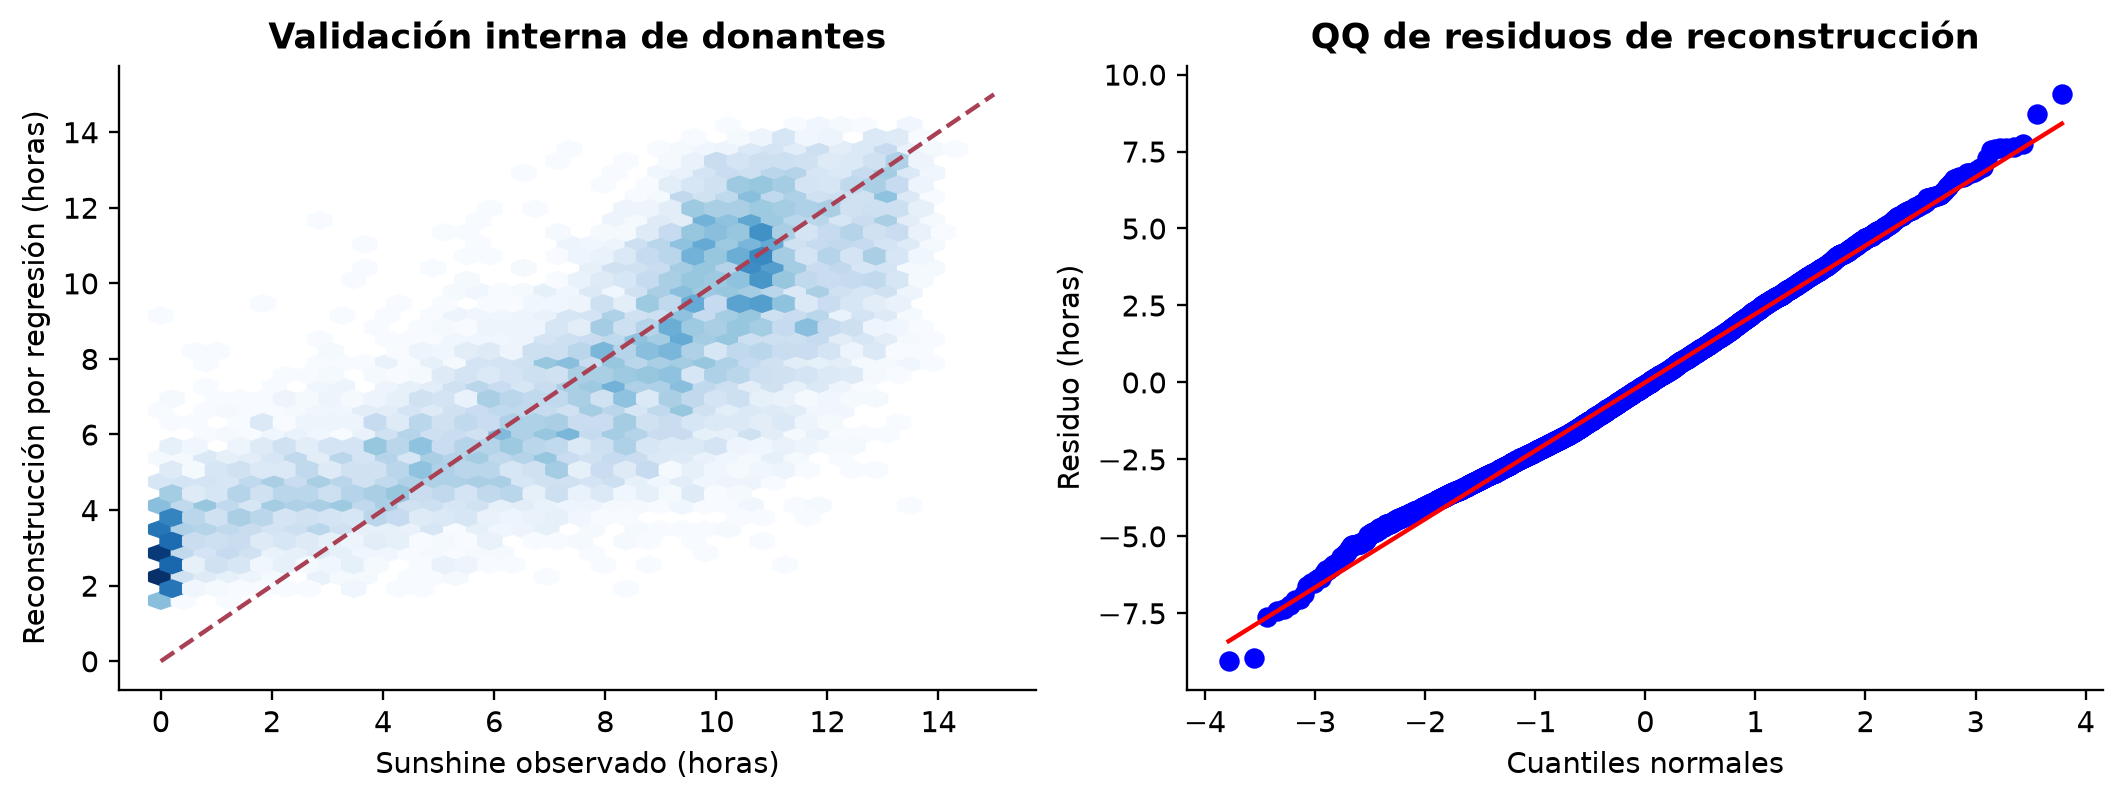

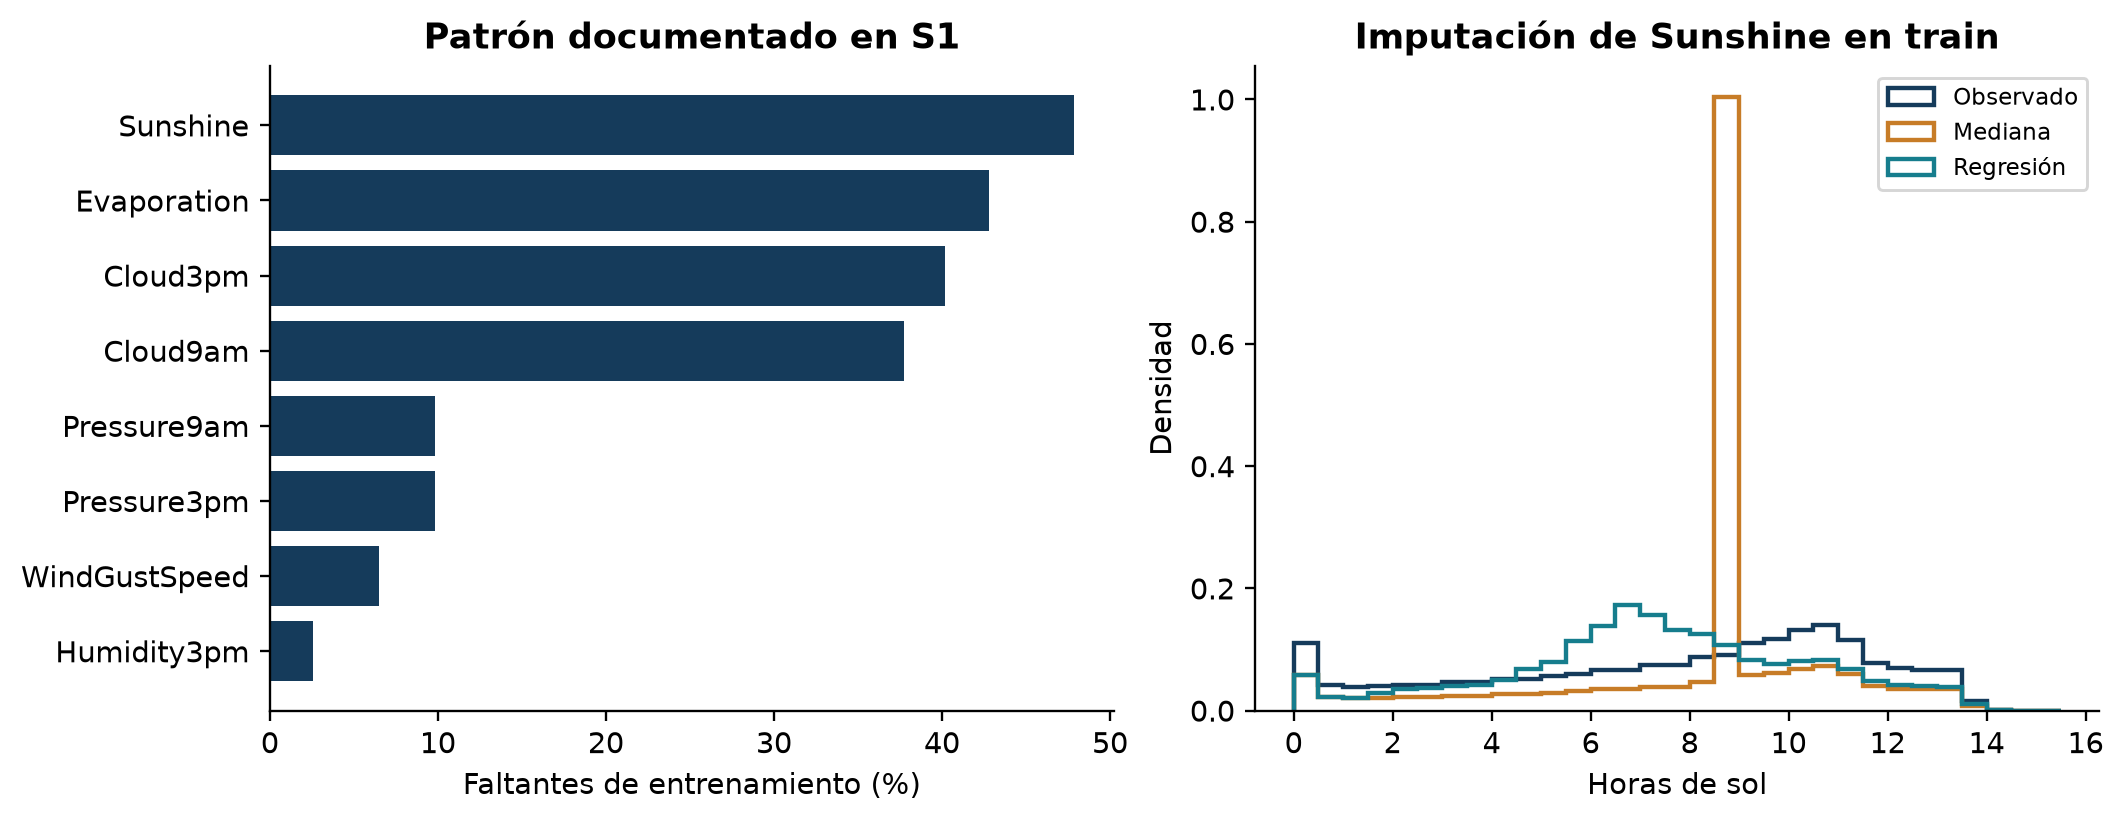

In [11]:
mostrar_figura("01_imputacion_regresion")
mostrar_figura("02_faltantes_distribuciones")

### Discriminación y errores de clasificación

Las matrices distinguen falsos negativos y falsas alarmas. Las métricas aparentes
de entrenamiento se presentan separadas de la validación OOF y de prueba.

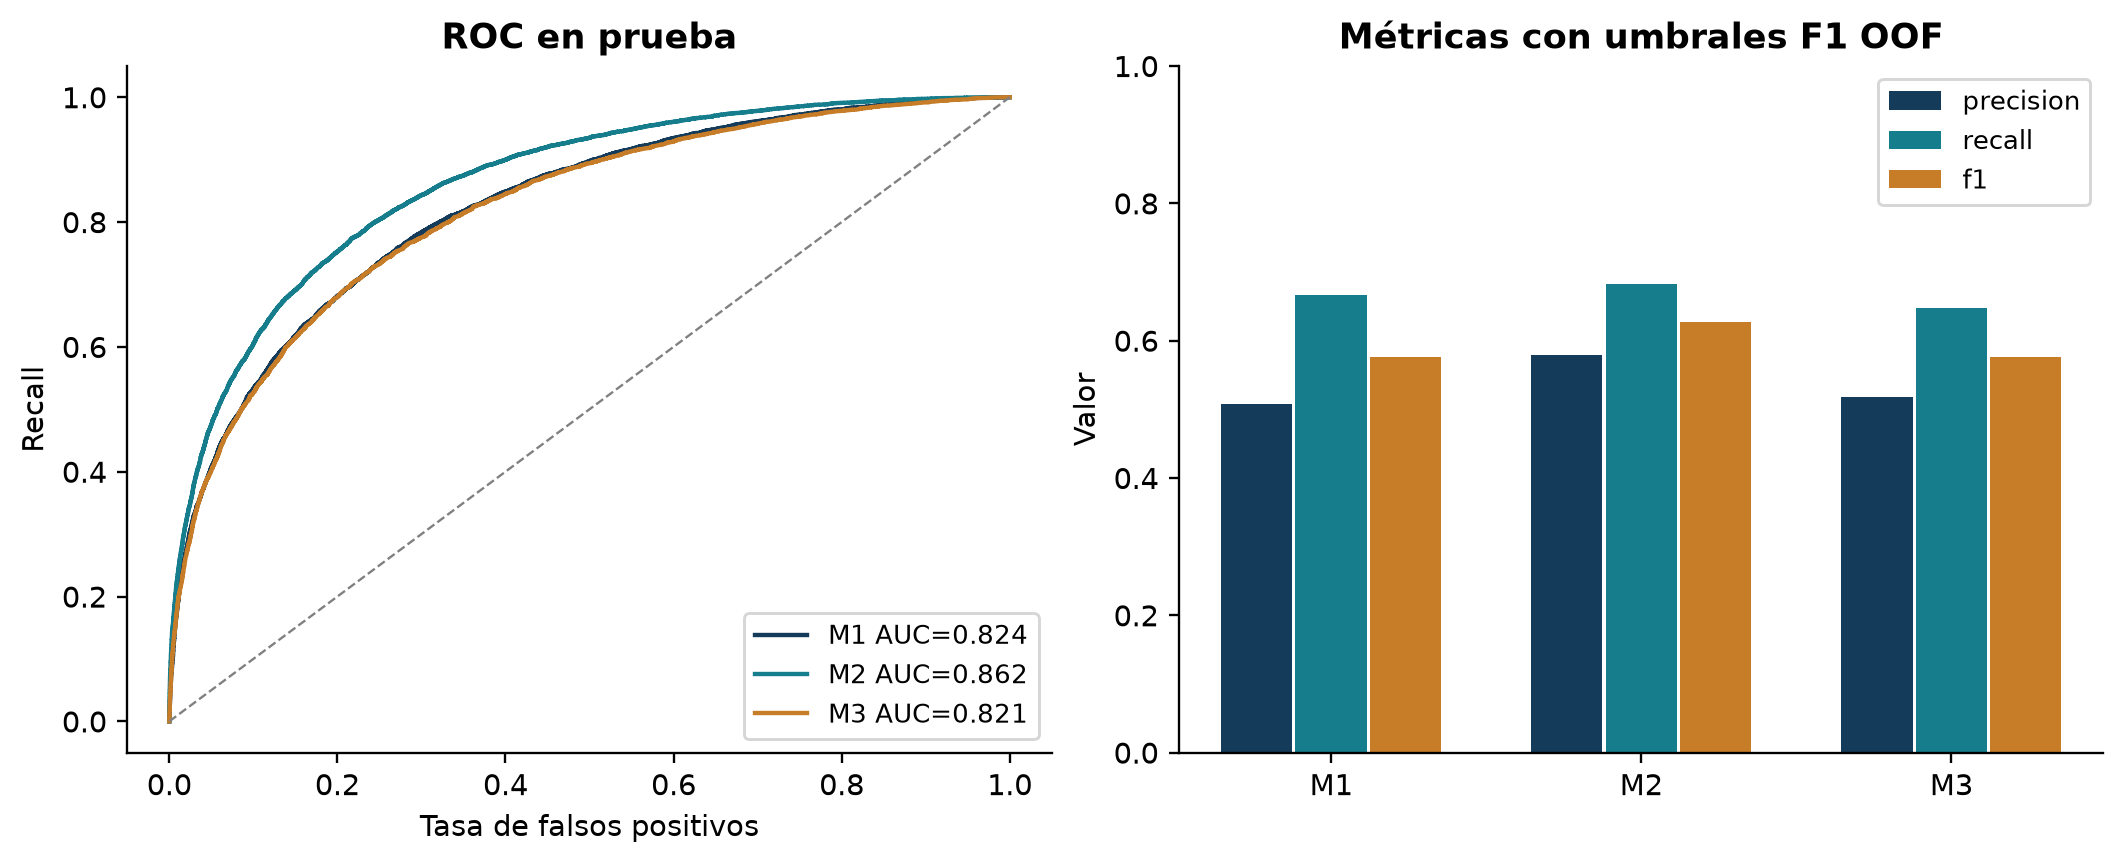

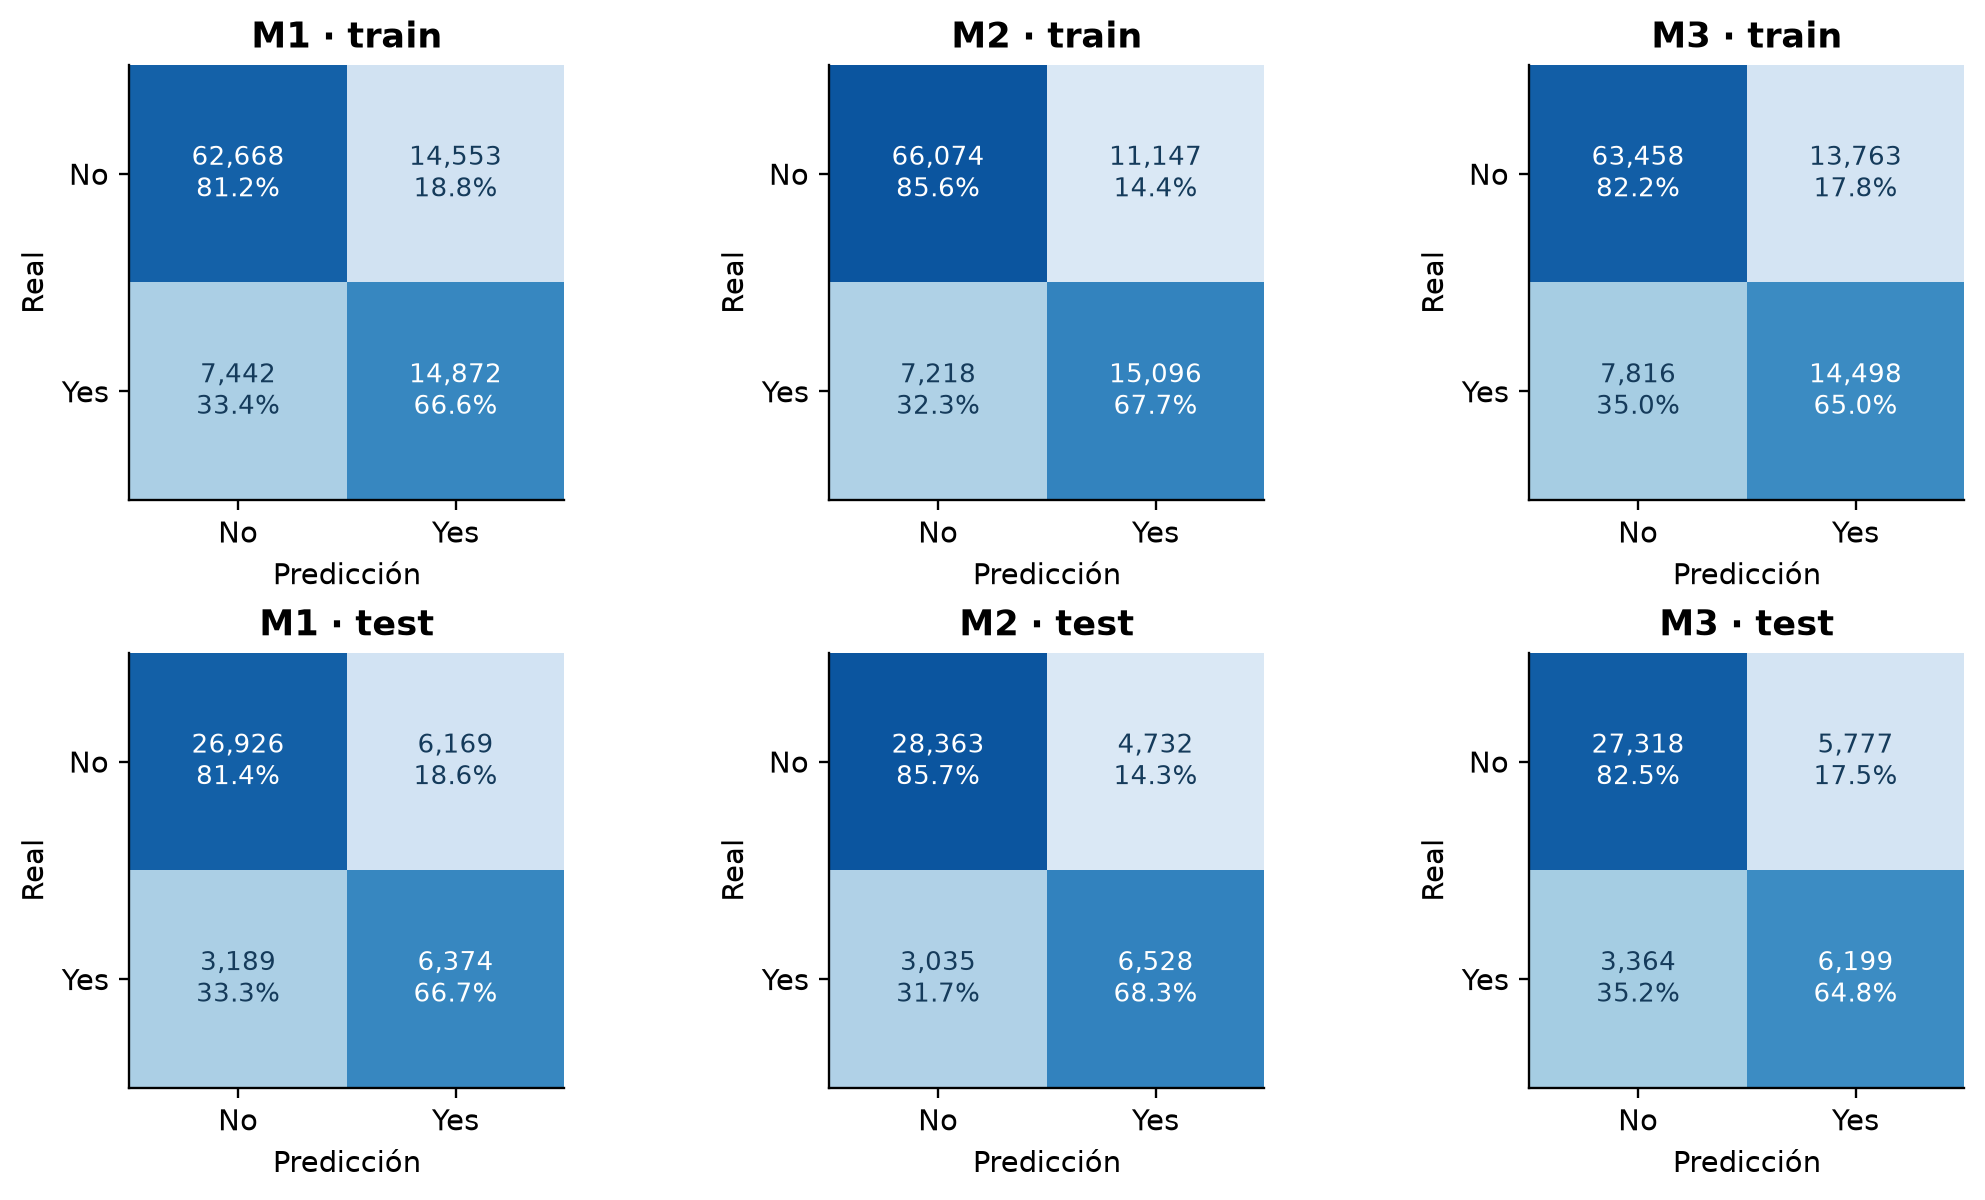

En esta prueba, AUC=0.8619, recall=68.26%, precision=57.98% y accuracy=81.79%. Quedan 3,035 días de lluvia sin detectar. F2 tenía recall=39.82% y accuracy=82.88%. La comparación cambia variables, imputación, pesos y umbral: no atribuye la mejora a una sola causa. El score ponderado necesita calibración antes de interpretarse como probabilidad operacional.

In [12]:
mostrar_figura("03_modelos_roc_metricas")
mostrar_figura("04_matrices_confusion")
display(Markdown(s3.interpretar(ctx, "rendimiento")))

### Incertidumbre de los coeficientes

Un IC de beta que incluye cero corresponde a un IC de OR que incluye uno.
La estabilidad del signo no demuestra causalidad ni valida la forma funcional.

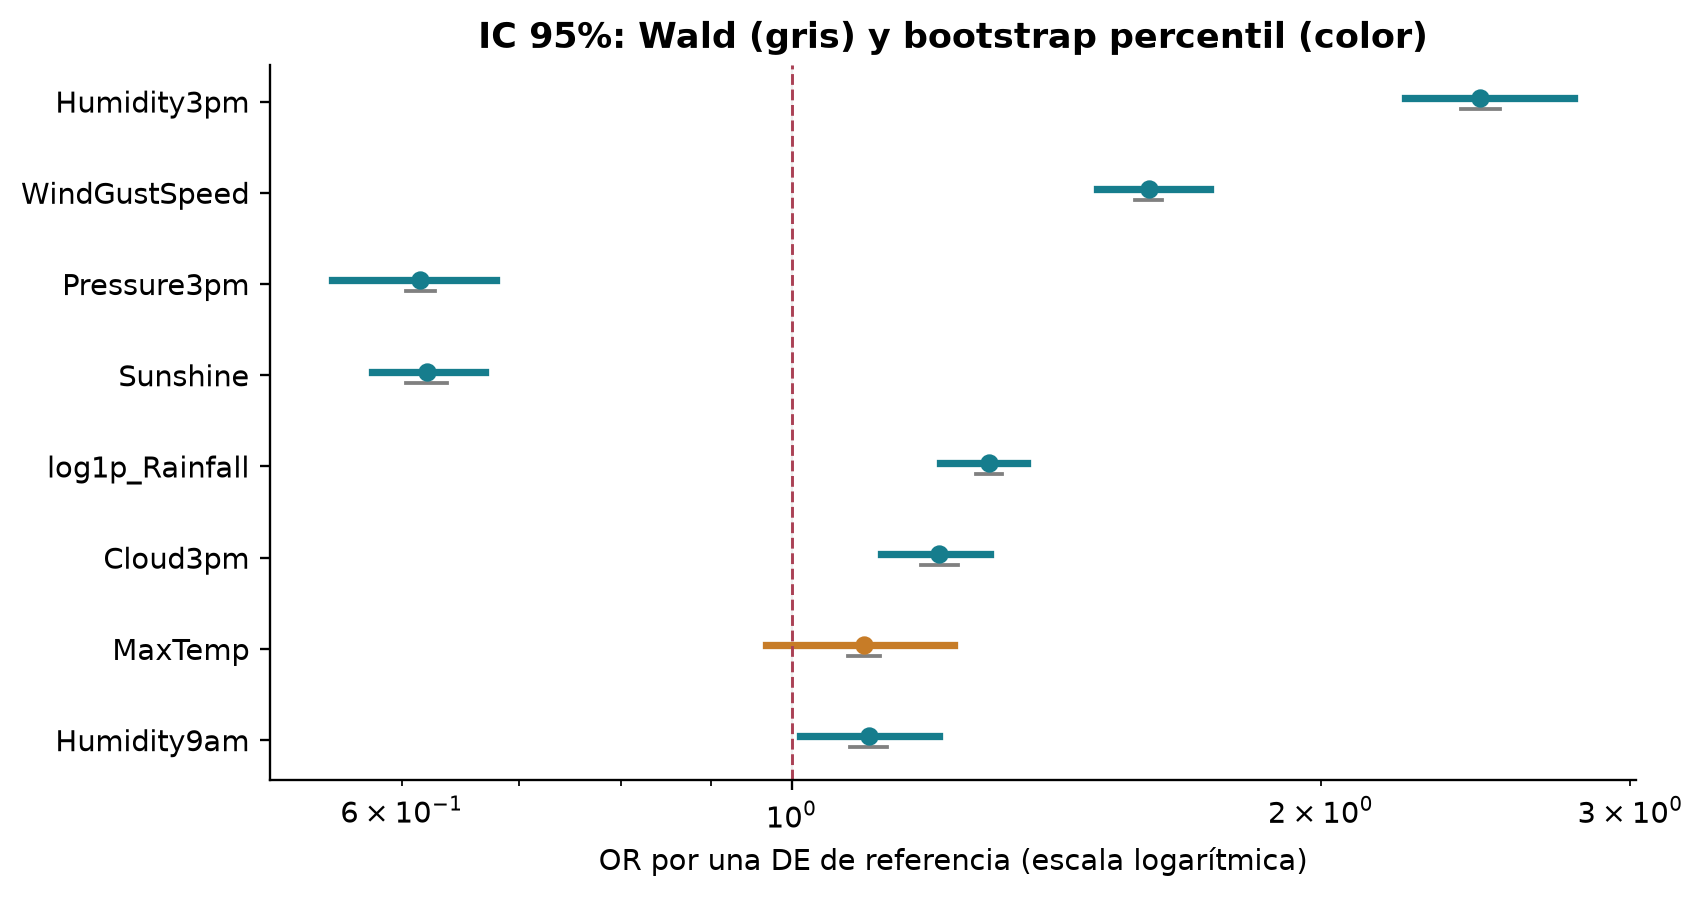

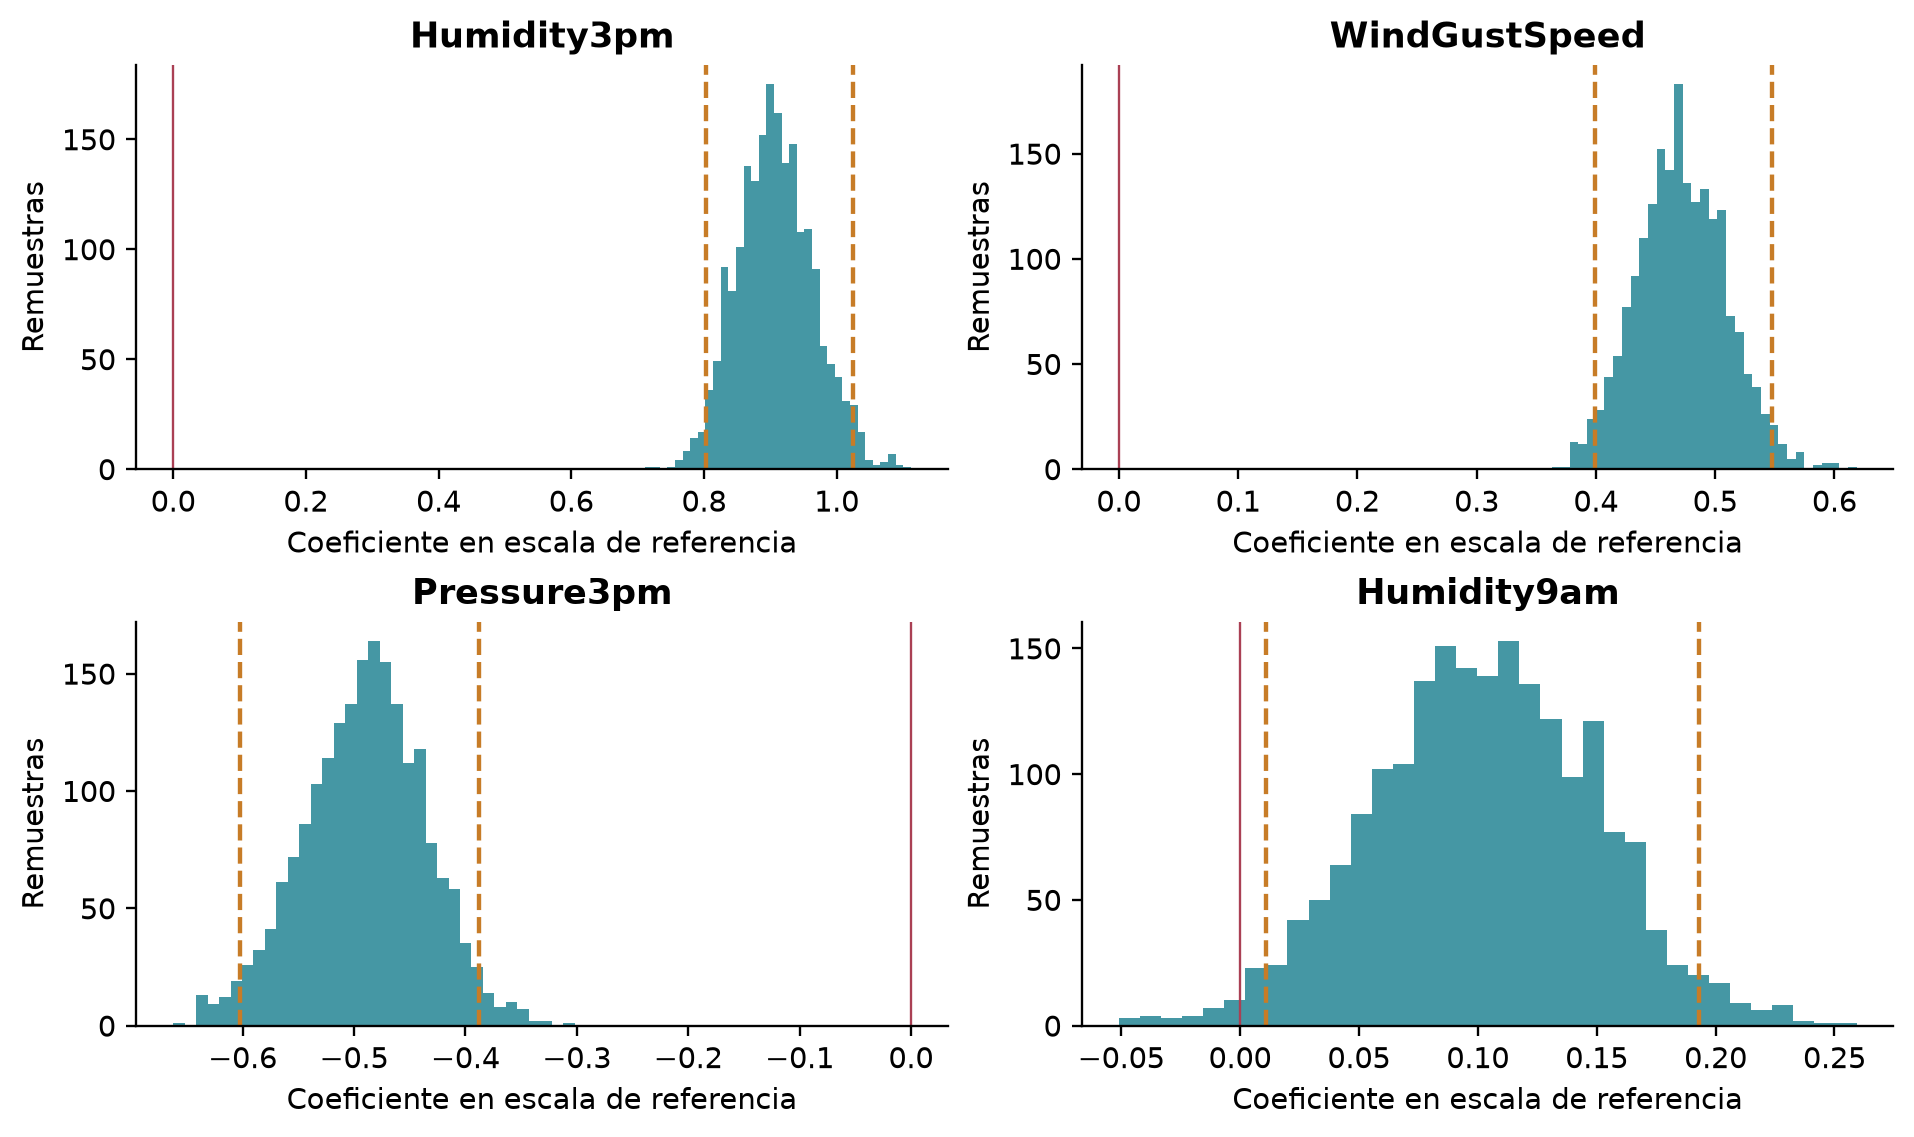

Se obtuvieron **2,000 réplicas válidas** y 0 fallos. Los intervalos percentil incluyen cero para: MaxTemp. Las DE y medianas se reajustan en cada remuestra. Las betas se expresan en una escala de referencia común. La frecuencia de signo es descriptiva, no una probabilidad posterior. La inferencia queda condicionada a los predictores seleccionados y a localidades aproximadamente independientes.

In [13]:
mostrar_figura("05_bootstrap_OR")
mostrar_figura("06_bootstrap_distribuciones")
display(Markdown(s3.interpretar(ctx, "bootstrap")))

### Diagnóstico y comparación de estrategias

La calibración puede diferir de la discriminación. La comparación de imputación
separa cobertura y desempeño sobre la misma población.

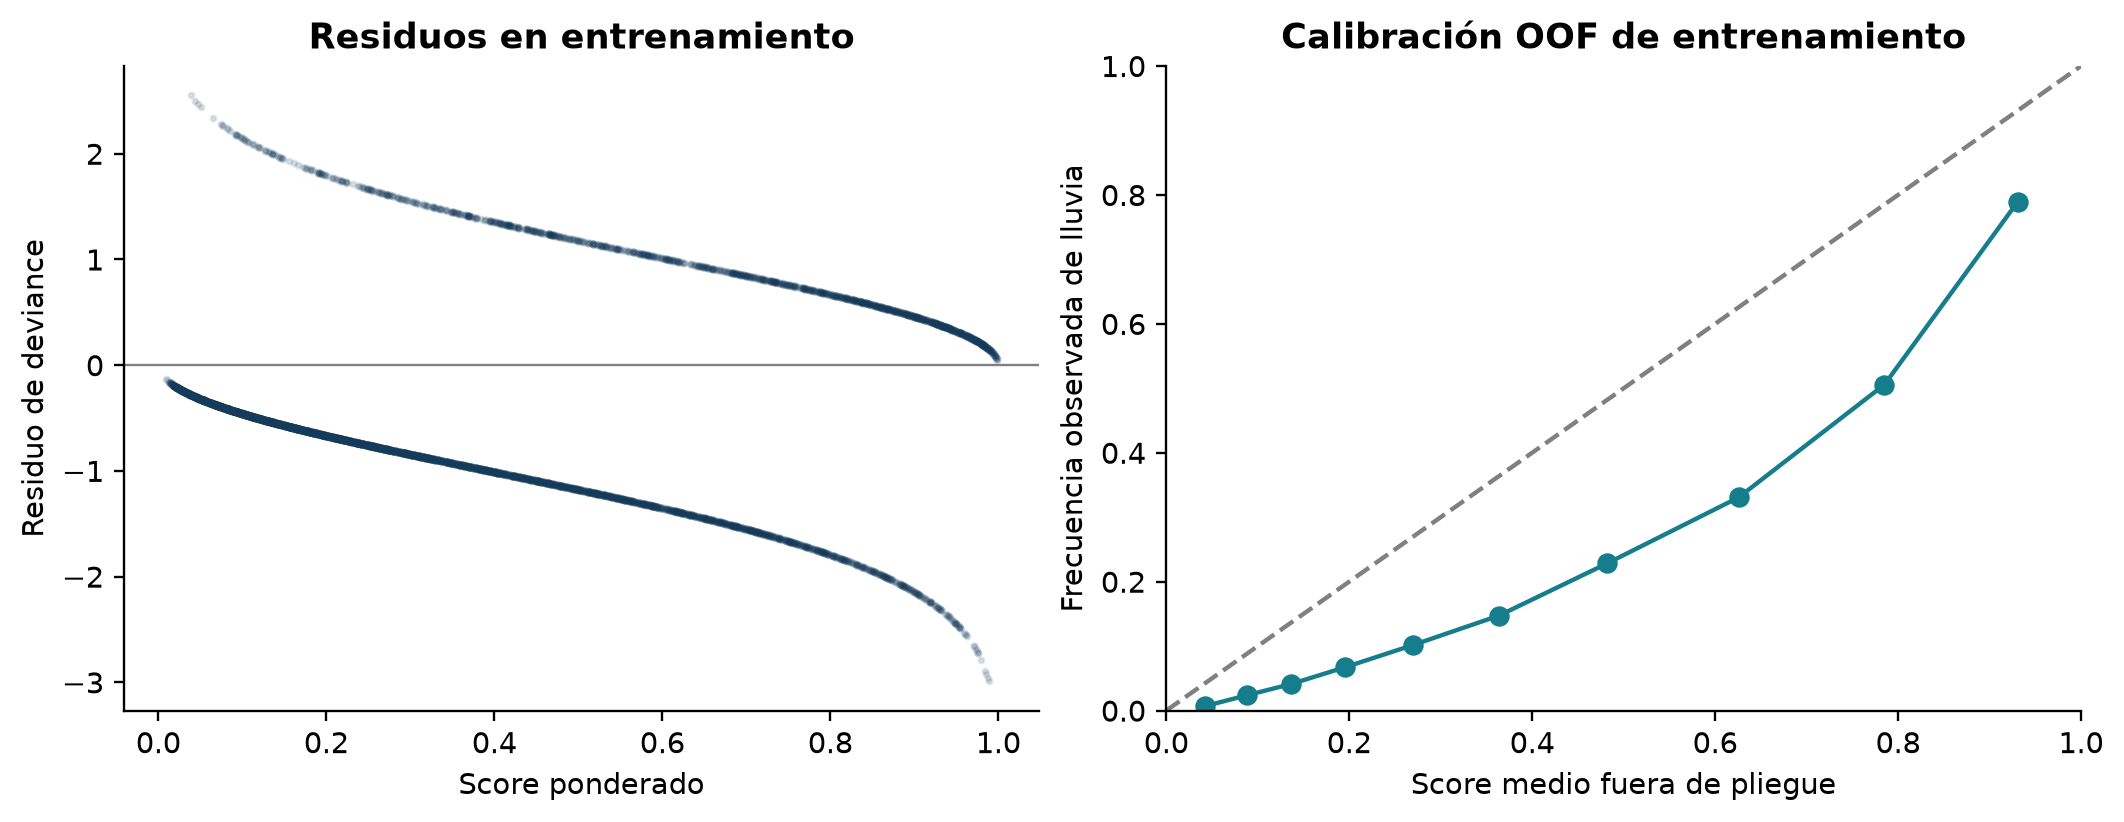

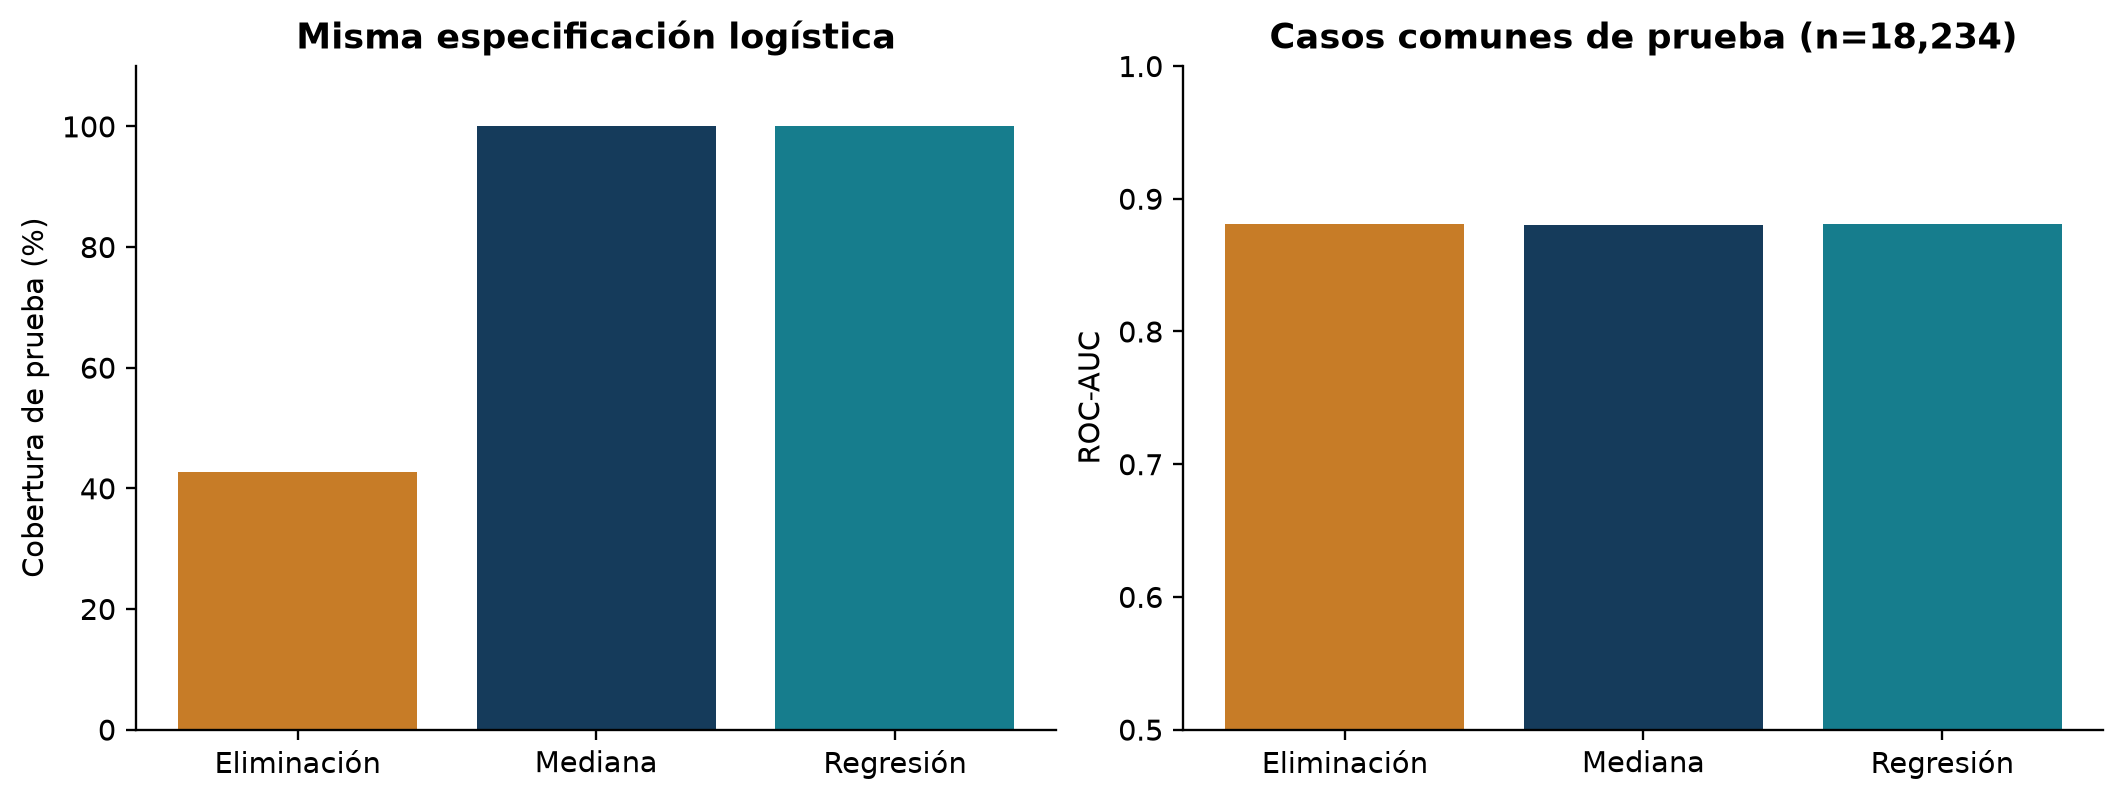

La eliminación cubre 42.74% de prueba y 27 localidades. Su AUC disponible no es directamente comparable con el de métodos que conservan toda la muestra. La tabla de casos comunes controla el conjunto evaluado. Los coeficientes se comparan por la misma DE de referencia, evitando confundir cambios de escala con cambios de efecto.

In [14]:
mostrar_figura("07_diagnostico")
mostrar_figura("08_impacto_imputacion")
display(Markdown(s3.interpretar(ctx, "impacto")))

### Capacidad bajo escenarios hipotéticos

La capacidad 95% traduce la simulación en una decisión explícita de planificación.
El supuesto iid limita su transferencia a secuencias meteorológicas reales.

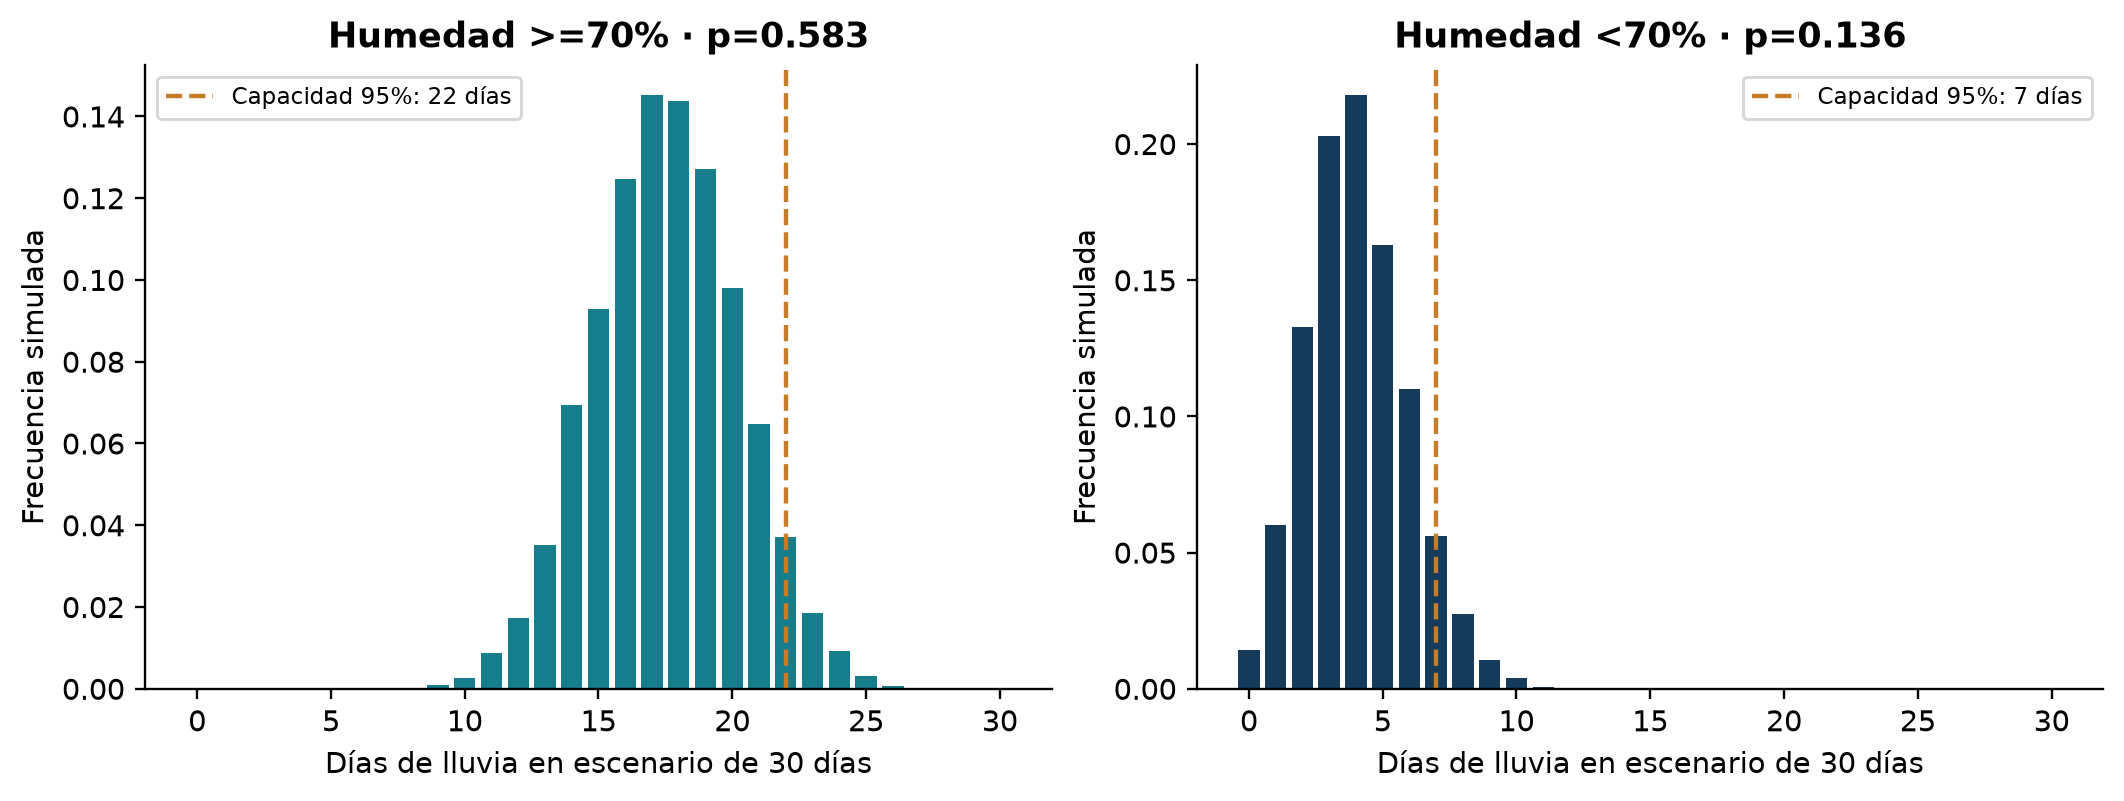

Para el escenario hipotético de 30 días con humedad >=70%, la capacidad al 95% es 22 días de lluvia; para humedad menor es 7. El riesgo de excedencia del 5% es un supuesto de planificación. Se usan frecuencias empíricas de entrenamiento y días iid. No representa un pronóstico de fechas futuras ni incorpora toda la incertidumbre climática o de estimación.

In [15]:
mostrar_figura("09_montecarlo_decision")
display(Markdown(s3.interpretar(ctx, "decision")))

## 11 Validación y evidencia reproducible

Se comprueban procedencia, partición, reproducción F2, respuesta excluida de
imputadores, equivalencia de bootstrap, métricas desde predicciones exportadas,
cuantiles e IC OR, figuras, conservación del CSV y decisiones fijadas antes de prueba.
Work y Windows generan registros distintos con versiones y hashes actuales.

In [16]:
evidencia = s3.validar(ctx)
display(s3.pd.Series(evidencia["controles"], name="Verificado"))

SUMATIVA 3 - EJECUCIÓN COMPLETA: CORRECTA
Controles numéricos y trazabilidad: correctos
CSV original sin modificaciones: True
Entorno ejecutado: windows
Evidencia: ejecucion_sumativa3_windows.json
Video grupal y entrega Canvas: requieren evidencia del grupo.


dataset_original_identificado                                  True
particion_70_30_estratificada_sin_solapamiento                 True
S2_conciliada_con_matriz_S1                                    True
F2_reproducida_metricas_y_matriz                               True
16_regresiones_imputacion_y_observados_intactos                True
imputadores_sin_RainTomorrow_ni_y                              True
Newton_conciliado_con_GLM_statsmodels                          True
seleccion_y_umbrales_congelados_antes_de_prueba                True
impacto_tres_estrategias_mismos_predictores_y_casos_comunes    True
bootstrap_ponderado_equivale_a_duplicar_localidades            True
bootstrap_replicas_validas_y_localidades                       True
bootstrap_escala_comun_coeficientes_y_OR                       True
simulacion_decision_calibrada_solo_train                       True
dataset_original_sin_modificaciones                            True
fuentes_analiticas_previas_sin_modificar        

## 12 Continuidad y referencias

La evidencia S1/S2 fundamenta selección e imputación. F2 aporta la referencia
predictiva. S3 compara procedimientos y cuantifica estabilidad. Antes de un uso
operacional se requieren datos y validación adecuados al horizonte, calibración,
costos de error y mecanismos de ausencia. El video debe demostrar participación
equitativa de los cuatro integrantes.

- Akaike, H. (1974). A new look at the statistical model identification.
  *IEEE Transactions on Automatic Control, 19*(6), 716–723.
  https://doi.org/10.1109/TAC.1974.1100705
- Cameron, A. C., & Miller, D. L. (2015). A practitioner's guide to cluster-robust
  inference. *Journal of Human Resources, 50*(2), 317–372.
  https://doi.org/10.3368/jhr.50.2.317
- Rubin, D. B. (1976). Inference and missing data. *Biometrika, 63*(3), 581–592.
  https://doi.org/10.1093/biomet/63.3.581
- Schwarz, G. (1978). Estimating the dimension of a model. *The Annals of
  Statistics, 6*(2), 461–464. https://doi.org/10.1214/aos/1176344136
- Scikit-learn developers. (s. f.). *compute_class_weight*.
  https://scikit-learn.org/stable/modules/generated/sklearn.utils.class_weight.compute_class_weight.html
- *Rain in Australia*. (s. f.). Kaggle.
  https://www.kaggle.com/datasets/jsphyg/weather-dataset-rattle-package

Las fuentes y versiones de S1/S2/F2 se registran en
`evidence/05_sumativa3/fuentes_base.json`; las decisiones y resultados actuales
se conservan en `results/05_sumativa3/resultados_validados_s3.json`.